# **Perbandingan Algoritma**

Di sini, dilakukan perbandingan antara ketiga algoritma: *hill climbing*, *simulated annealing*, dan *genetic algorithm*. 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

from src import *
import matplotlib.pyplot as plt

## **Dataset**

Akan digunakan *dataset* berikut dengan $3$ truk dan $23$ paket. 

In [3]:
trucks = [
   Truck("T1", 10, 20, 5, 200),
   Truck("T2", 8, 12, 4, 150),
   Truck("T3", 6, 10, 3, 100),
]

packages = [
   Package("S1", 1, 1, 1, 50, 2, False, 1),
   Package("S2", 1, 2, 1, 45, 3, False, 3),
   Package("S3", 2, 1, 1, 40, 2, True, 2),
   Package("S4", 1, 1, 2, 35, 1, False, 4),
   Package("S5", 2, 2, 1, 55, 4, False, 1),

   Package("M1", 3, 4, 2, 80, 10, False, 5),
   Package("M2", 2, 3, 2, 70, 8, True, 2),
   Package("M3", 4, 3, 1, 65, 12, False, 3),
   Package("M4", 3, 3, 3, 90, 15, False, 6),
   Package("M5", 2, 4, 2, 75, 9, False, 1),
   Package("M6", 3, 2, 2, 60, 11, True, 4),
   Package("M7", 4, 2, 3, 85, 14, False, 2),

   Package("L1", 5, 6, 3, 120, 25, False, 7),
   Package("L2", 4, 5, 2, 100, 20, False, 3),
   Package("L3", 6, 4, 2, 110, 22, True, 5),
   Package("L4", 5, 5, 3, 130, 30, False, 2),
   Package("L5", 4, 4, 4, 95, 18, False, 4),

   Package("H1", 3, 3, 2, 140, 35, False, 1),
   Package("H2", 2, 2, 2, 105, 28, False, 6),

   Package("B1", 6, 8, 3, 30, 40, False, 7),
   Package("B2", 5, 7, 4, 25, 35, False, 5),

   Package("F1", 2, 3, 1, 115, 6, True, 1),
   Package("F2", 3, 2, 2, 100, 7, True, 1),
]

initial_state = State(packages, trucks, init="random_feasible")
draw_state(initial_state)

Sebagai kontrol, iterasi maksimum adalah $200$ dan fungsi objektif adalah `MaxValueObjective`. 

In [4]:
max_iter = 200
objective = MaxValueObjective()

results = []

## **Hill Climbing**

Pertama, diuji algoritma _hill climbing_ pada _dataset_ di atas. 

#### **Steepest Ascent Hill Climbing** 

Berikut hasil algoritma *steepest ascent hill climbing*. 

In [5]:
steepest_ascent_solver = SteepestAscent(objective, max_iterations=max_iter)
steepest_ascent_result = steepest_ascent_solver.solve(initial_state)

results.append(steepest_ascent_result)

In [6]:
print(steepest_ascent_result)
draw_state(steepest_ascent_result.final_state)

Solver: SteepestAscent
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 55.168s
Total Iterations: 9
Initial Objective: 1005.00
Final Objective: 1765.00


#### **Stochastic Hill Climbing** 

Berikut hasil algoritma *stochastic hill climbing*. 

In [7]:
stochastic_solver = Stochastic(objective, max_iterations=max_iter)
stochastic_result = stochastic_solver.solve(initial_state)

results.append(stochastic_result)

In [8]:
print(stochastic_result)
draw_state(stochastic_result.final_state)

Solver: Stochastic
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 0.009s
Total Iterations: 200
Initial Objective: 1005.00
Final Objective: 1185.00
----------------------------------------------------------------------------------------------------
Random Successor Iterations : [16, 26, 48, 77, 2]


#### **Sideways Move Hill Climbing** 

Berikut hasil algoritma *sideways move hill climbing*. Digunakan `max_sideways_moves=10`.

In [9]:
sideways_move_solver = SidewaysMove(objective, max_sideways_moves=10, max_iterations=max_iter)
sideways_move_result = sideways_move_solver.solve(initial_state)

results.append(sideways_move_result)

In [10]:
print(sideways_move_result)
draw_state(sideways_move_result.final_state)

Solver: SidewaysMove
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 130.739s
Total Iterations: 19
Initial Objective: 1005.00
Final Objective: 1765.00
----------------------------------------------------------------------------------------------------
Sideways Moves       : 10


#### **Random Restart Hill Climbing** 

Berikut hasil algoritma *random restart hill climbing*. Digunakan `max_restarts=15`.

In [11]:
random_restart_solver = RandomRestart(objective, max_restarts=15, max_iterations_per_restart=max_iter)
random_restart_result = random_restart_solver.solve(initial_state)

results.append(random_restart_result)

In [12]:
print(random_restart_result)
draw_state(random_restart_result.final_state)

Solver: RandomRestart
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 1248.689s
Total Iterations: 186
Initial Objective: 620.00
Final Objective: 1820.00
----------------------------------------------------------------------------------------------------
Total Restarts       : 15
Iterations Per Restart : [15 values]
Initial State History : [15 values]
All Objective History : [15 values]
Runtime History      : [15 values]


## **Simulated Annealing**

Kedua, diuji algoritma _simulated annealing_ pada _dataset_ di atas. Digunakan `schedule=RationalSchedule(100, 0.001)`.

In [13]:
schedule = RationalSchedule(100, 0.001) 

Berikut hasil algoritma *simulated annealing*. 

In [30]:
simulated_annealing_solver = SimulatedAnnealing(objective, schedule=schedule, max_iterations=max_iter)
simulated_annealing_result = simulated_annealing_solver.solve(initial_state)

results.append(simulated_annealing_result)

In [31]:
print(simulated_annealing_result)
draw_state(simulated_annealing_result.final_state)

Solver: SimulatedAnnealing
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 0.027s
Total Iterations: 200
Initial Objective: 1005.00
Final Objective: 1080.00
----------------------------------------------------------------------------------------------------
Probability History  : [200 values]


## **Genetic Algorithm**

Ketiga, diuji algoritma _genetic algorithm_ pada _dataset_ di atas. Digunakan `population_size=5`.

In [16]:
genetic_algorithm_solver = GeneticAlgorithm(objective, population_size=5, max_generations=max_iter)
genetic_algorithm_result = genetic_algorithm_solver.solve(initial_state)

results.append(genetic_algorithm_result)

In [17]:
print(simulated_annealing_result)
draw_state(simulated_annealing_result.final_state)

Solver: SimulatedAnnealing
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 2.347s
Total Iterations: 10,000
Initial Objective: 1005.00
Final Objective: 1765.00
----------------------------------------------------------------------------------------------------
Probability History  : [10000 values]


## **Perbandingan**

Berikutnya, dibuat beberapa grafik untuk melihat perbedaan antara solusi setiap algoritma. 

In [69]:
print(f"{'Solver':<18} | {'Runtime (s)'} | {'Final Objective':<10}")
print("-" * 50)

for result in results:
    print(f"{result.solver:<18} | {result.runtime:<11.3f} | {result.objective_history[-1]:<10}")

Solver             | Runtime (s) | Final Objective
--------------------------------------------------
SteepestAscent     | 55.168      | 1765      
Stochastic         | 0.009       | 1185      
SidewaysMove       | 130.739     | 1765      
RandomRestart      | 1248.689    | 1820      
GeneticAlgorithm   | 0.573       | 1595      
SimulatedAnnealing | 0.027       | 1080      


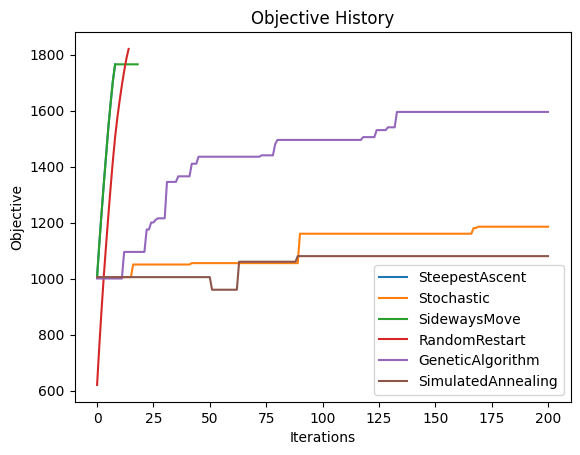

In [37]:
for result in results:
   plt.plot(result.objective_history, label=result.solver)

plt.title('Objective History')
plt.xlabel('Iterations')
plt.ylabel('Objective')
plt.legend()
plt.show()